# 05 — Primary essentiality comparison

**This is the first notebook that reads the outcome.** `CRISPRGeneEffect.csv` is loaded
here and nowhere earlier. The pre-specification was frozen at `81745ed` and amended to
v1.1 at `a63d56c`, both before this notebook ran.

Per prespec §5 and §4d, two contrasts run in parallel with the same test and the same
output format:

| Contrast | Split | Role |
|---|---|---|
| `primary_median_8v8` | 8 v 8 | **primary** |
| `sensitivity_tertile_3v13` | 3 v 13 | pre-specified sensitivity (superseded §4a primary) |

Endpoint, sign convention binding throughout:

```
composite = mean(POLD3, RAD52, SMARCAL1) - mean(BRCA1, BRCA2, RAD51)
```

Chronos gene effect is more negative when a gene is more essential, so the hypothesis
predicts the TCAB1-low composite is **more negative**: Cliff's delta < 0.

Tests are two-sided exact Mann-Whitney. Primary is one test, no correction. The six
per-gene comparisons carry BH-FDR across exactly those six (§6.1).

**Read prespec §5a before interpreting anything here:** at 8v8 the smallest |delta| that
can reach two-sided p<0.05 is 0.594, and at 3v13 it is roughly 0.90.

## 1 — Header and provenance

In [1]:
import sys, random, time, warnings
from pathlib import Path

import numpy as np

random.seed(42)
np.random.seed(42)

_cwd = Path('.').resolve()
ROOT = _cwd if (_cwd / 'src').is_dir() else _cwd.parent
assert (ROOT / 'src').is_dir(), f"Cannot locate src/ -- tried {_cwd} and {_cwd.parent}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(f'ROOT: {ROOT}')

warnings.filterwarnings('ignore', category=FutureWarning)

import pandas as pd
from src.utils import log_versions, run_timestamp, record_provenance, write_report, write_sha256_manifest, git_head

RUN_TIMESTAMP = run_timestamp()
VERSIONS = log_versions(['pandas', 'numpy', 'scipy', 'sklearn', 'matplotlib'])
print(f'Run: {RUN_TIMESTAMP}')
assert sys.version_info[:2] == (3, 12), f'Expected Python 3.12, got {sys.version_info[:2]}'
print(f'Python: {sys.version.split()[0]}')

FREEZE_COMMIT_V10 = '81745ed'
FREEZE_COMMIT_V11 = 'a63d56c'
print(f'\nprespec v1.0 freeze : {FREEZE_COMMIT_V10}')
print(f'prespec v1.1 amend  : {FREEZE_COMMIT_V11}')
print(f'current git HEAD    : {git_head()}')

ROOT: /Users/rinatrizvanov/Desktop/Projects/Project 1 - Comp Bio for Osteosarcoma/tcab1-bir-dependency


Library versions:
  pandas: 2.3.3
  numpy: 2.5.4
  scipy: 1.18.1
  sklearn: 1.9.1
  matplotlib: 3.11.2
Run: 2026-10-12T00:29:16Z
Python: 3.12.13

prespec v1.0 freeze : 81745ed
prespec v1.1 amend  : a63d56c
current git HEAD    : a63d56c80c9930b9a5b517af819adedd6d970aa7


## 2 — Load the stratification from notebook 04

In [2]:
from src.utils import PROCESSED_DIR
from src.cohort import build_cohort, assert_all, gold_only
from src.stratify import LOW_LABEL, INTACT_LABEL

strata = pd.read_csv(PROCESSED_DIR / 'tcab1_strata.csv', index_col='ModelID')
strata_neg = pd.read_csv(PROCESSED_DIR / 'tcab1_strata_alt_negative.csv', index_col='ModelID')

cohort = build_cohort()
assert_all(cohort)
alt_ids = cohort.alt_positive['ModelID'].tolist()
neg_ids = cohort.alt_negative['ModelID'].tolist()
assert set(strata.index) == set(alt_ids), 'strata/cohort mismatch'

CONTRASTS = {
    'primary_median_8v8': 'arm_primary_8v8',
    'sensitivity_tertile_3v13': 'arm_tertile_3v13',
}
for label, col in CONTRASTS.items():
    print(f'{label:<28s} {strata[col].value_counts().to_dict()}')
print(f'{"alt_negative_median":<28s} {strata_neg["arm_median"].value_counts().to_dict()}')

primary_median_8v8           {'TCAB1-low': 8, 'TCAB1-intact': 8}
sensitivity_tertile_3v13     {'TCAB1-intact': 13, 'TCAB1-low': 3}
alt_negative_median          {'TCAB1-intact': 5, 'TCAB1-low': 4}


## 3 — Load the outcome

First and only point at which gene-effect values enter the analysis.

In [3]:
from src.dependency_stats import (
    BIR_GENES, HR_GENES, SIX_GENES,
    load_gene_effects, composite_score, compare_groups, per_gene_comparisons,
)

effects = load_gene_effects([*alt_ids, *neg_ids], SIX_GENES)
print(f'loaded gene effects: {effects.shape[0]} lines x {effects.shape[1]} genes')
print(f'BIR genes: {BIR_GENES}')
print(f'HR  genes: {HR_GENES}')
print()
print(effects.round(3).to_string())

loaded gene effects: 25 lines x 6 genes
BIR genes: ('POLD3', 'RAD52', 'SMARCAL1')
HR  genes: ('BRCA1', 'BRCA2', 'RAD51')

            POLD3  RAD52  SMARCAL1  BRCA1  BRCA2  RAD51
ModelID                                                
ACH-000082 -2.076  0.117    -1.086 -0.466 -0.228 -1.156
ACH-000364 -1.483  0.093    -0.138 -0.635 -0.832 -1.237
ACH-000410 -1.986  0.041    -0.772 -0.808 -0.149 -1.010
ACH-001526 -1.325 -0.022    -0.556 -0.584 -0.297 -1.137
ACH-001715 -1.689 -0.416    -0.555 -0.150 -0.375 -1.013
ACH-002067 -1.714  0.378    -0.309 -0.365 -0.420 -1.015
ACH-002433 -1.370 -0.028    -1.104 -0.563 -1.221 -1.664
ACH-002471 -1.779  0.053    -0.370 -0.208 -0.017 -0.966
ACH-002688 -2.123  0.230    -0.791 -0.165 -0.046 -0.611
ACH-002690 -2.015 -0.108    -0.275 -1.042 -0.942 -1.133
ACH-002834 -1.560  0.137    -1.027 -0.546 -0.270 -1.122
ACH-003171 -1.572 -0.154    -0.039 -1.841 -0.393 -0.913
ACH-003178 -2.413 -0.011    -0.140 -0.647 -0.971 -1.517
ACH-003185 -1.518 -0.014     0.224 -0.

## 4 — Composite endpoint

In [4]:
composite = composite_score(effects)
summary = pd.DataFrame({
    'cell_line': pd.concat([cohort.alt_positive, cohort.alt_negative])
                   .set_index('ModelID')['StrippedCellLineName'],
    'BIR_mean': effects[list(BIR_GENES)].mean(axis=1),
    'HR_mean': effects[list(HR_GENES)].mean(axis=1),
    'composite': composite,
})
summary['alt'] = ['ALT+' if m in set(alt_ids) else 'ALT-' for m in summary.index]
summary['arm_8v8'] = strata['arm_primary_8v8'].reindex(summary.index)
summary['arm_3v13'] = strata['arm_tertile_3v13'].reindex(summary.index)
summary['WRAP53'] = strata['WRAP53_log2tpm'].reindex(summary.index)
print(summary.sort_values(['alt', 'WRAP53']).round(4).to_string())

                  cell_line  BIR_mean  HR_mean  composite   alt       arm_8v8      arm_3v13  WRAP53
ModelID                                                                                            
ACH-002834            OS384   -0.8164  -0.6461    -0.1703  ALT+     TCAB1-low     TCAB1-low  0.0000
ACH-003185           NRHOS4   -0.4362  -0.9601     0.5240  ALT+     TCAB1-low     TCAB1-low  0.0000
ACH-003171           NRHOS1   -0.5884  -1.0490     0.4605  ALT+     TCAB1-low     TCAB1-low  2.7481
ACH-002433    CCLFPEDS0019T   -0.8340  -1.1495     0.3154  ALT+     TCAB1-low  TCAB1-intact  3.3356
ACH-003178           NRHOS2   -0.8547  -1.0448     0.1901  ALT+     TCAB1-low  TCAB1-intact  3.4266
ACH-001715            CAL72   -0.8867  -0.5129    -0.3738  ALT+     TCAB1-low  TCAB1-intact  3.4586
ACH-003573             C337   -0.6351  -1.1193     0.4842  ALT+     TCAB1-low  TCAB1-intact  3.4838
ACH-002688            OS457   -0.8949  -0.2737    -0.6212  ALT+     TCAB1-low  TCAB1-intact  3.4885


## 5 — Primary test, both contrasts in parallel

Same test, same output format, both into the final report (prespec §4d).

In [5]:
results = {}
for label, col in CONTRASTS.items():
    arms = strata[col]
    low = composite.loc[arms.index[arms == LOW_LABEL]]
    intact = composite.loc[arms.index[arms == INTACT_LABEL]]
    res = compare_groups(low, intact, name=label)
    results[label] = res
    print(f'=== {label} ===')
    print(f'  n: {res.n_low} low vs {res.n_intact} intact')
    print(f'  median composite: low {res.median_low:+.4f}   intact {res.median_intact:+.4f}')
    print(f'  Mann-Whitney U = {res.u_statistic:.1f}   p = {res.p_value:.4g}  [{res.mwu_method}]')
    print(f"  Cliff's delta  = {res.cliffs_delta:+.4f}  95% CI [{res.delta_ci_low:+.4f}, {res.delta_ci_high:+.4f}]  ({res.delta_magnitude})")
    print(f'  Hodges-Lehmann = {res.hodges_lehmann:+.4f} Chronos units')
    print(f'  direction as predicted (delta<0): {res.direction_as_predicted}')
    print()

=== primary_median_8v8 ===
  n: 8 low vs 8 intact
  median composite: low +0.2528   intact -0.0093
  Mann-Whitney U = 41.0   p = 0.3823  [exact]
  Cliff's delta  = +0.2812  95% CI [-0.3125, +0.8438]  (small)
  Hodges-Lehmann = +0.1865 Chronos units
  direction as predicted (delta<0): False

=== sensitivity_tertile_3v13 ===
  n: 3 low vs 13 intact
  median composite: low +0.4605   intact +0.0384
  Mann-Whitney U = 30.0   p = 0.1893  [exact]
  Cliff's delta  = +0.5385  95% CI [-0.2308, +1.0000]  (large)
  Hodges-Lehmann = +0.2704 Chronos units
  direction as predicted (delta<0): False



## 6 — Minimum detectable effect, restated against the observed result

Prespec §5a committed these before any outcome was read.

In [6]:
from src.criteria import MIN_DETECTABLE_DELTA, ALPHA

print(f'{"contrast":<28s} {"observed delta":>15s} {"min |delta| for p<0.05":>24s} {"reachable?":>12s}')
for label, key in [('primary_median_8v8', '8v8'), ('sensitivity_tertile_3v13', '3v13')]:
    res = results[label]
    floor = MIN_DETECTABLE_DELTA.get(key)
    if floor is None:
        # 3v13 was not tabulated in v1.0; compute it exactly now.
        import itertools
        from scipy.stats import mannwhitneyu
        nlow, nint = res.n_low, res.n_intact
        best = None
        for combo in itertools.combinations(range(nlow + nint), nlow):
            s = set(combo)
            x = np.array([r for r in range(nlow + nint) if r in s], float)
            y = np.array([r for r in range(nlow + nint) if r not in s], float)
            if mannwhitneyu(x, y, alternative='two-sided', method='exact').pvalue < ALPHA:
                u = sum(1 for a in x for b in y if a > b)
                d = abs(2 * u / (nlow * nint) - 1)
                best = d if best is None else min(best, d)
        floor = best
        MIN_DETECTABLE_DELTA[key] = floor
    print(f'{label:<28s} {res.cliffs_delta:>+15.4f} {floor:>24.3f} '
          f'{"yes" if abs(res.cliffs_delta) >= floor else "NO":>12s}')

contrast                      observed delta   min |delta| for p<0.05   reachable?
primary_median_8v8                   +0.2812                    0.594           NO
sensitivity_tertile_3v13             +0.5385                    0.795           NO


## 7 — Six per-gene comparisons with BH-FDR (§6.1)

In [7]:
per_gene = {}
for label, col in CONTRASTS.items():
    arms = strata[col]
    frame = per_gene_comparisons(
        effects,
        arms.index[arms == LOW_LABEL].tolist(),
        arms.index[arms == INTACT_LABEL].tolist(),
    )
    per_gene[label] = frame
    print(f'=== {label} ===')
    show = frame[['name', 'gene_set', 'median_low', 'median_intact', 'p_value',
                  'q_value', 'cliffs_delta', 'delta_ci_low', 'delta_ci_high',
                  'hodges_lehmann', 'delta_magnitude']]
    print(show.round(4).to_string(index=False))
    print()

=== primary_median_8v8 ===
    name gene_set  median_low  median_intact  p_value  q_value  cliffs_delta  delta_ci_low  delta_ci_high  hodges_lehmann delta_magnitude
   POLD3      BIR     -1.6079        -1.7463   0.9591   0.9591       -0.0312       -0.6250         0.5625         -0.0401      negligible
   RAD52      BIR     -0.0133         0.0468   0.2786   0.9591       -0.3438       -0.8750         0.2500         -0.0660          medium
SMARCAL1      BIR     -0.4020        -0.4628   0.7209   0.9591        0.1250       -0.5000         0.7188          0.0794      negligible
   BRCA1       HR     -0.5548        -0.5252   0.9591   0.9591       -0.0312       -0.5938         0.5938         -0.0185      negligible
   BRCA2       HR     -0.5485        -0.3582   0.4418   0.9591       -0.2500       -0.7812         0.3438         -0.1388           small
   RAD51       HR     -1.3193        -1.0830   0.5737   0.9591       -0.1875       -0.7500         0.4688         -0.2177           small



=== sensitivity_tertile_3v13 ===
    name gene_set  median_low  median_intact  p_value  q_value  cliffs_delta  delta_ci_low  delta_ci_high  hodges_lehmann delta_magnitude
   POLD3      BIR     -1.5598        -1.7136   0.3643      1.0        0.3846       -0.0808         0.8462          0.1710          medium
   RAD52      BIR     -0.0142        -0.0091   0.7036      1.0       -0.1795       -0.8974         0.6923         -0.0460           small
SMARCAL1      BIR     -0.0390        -0.5547   0.2964      1.0        0.4359       -0.6923         1.0000          0.3618          medium
   BRCA1       HR     -0.5461        -0.5635   0.7036      1.0       -0.1795       -1.0000         0.5897         -0.1813           small
   BRCA2       HR     -0.3931        -0.4198   1.0000      1.0       -0.0256       -0.6410         0.6410         -0.0178      negligible
   RAD51       HR     -1.1220        -1.1328   0.9000      1.0        0.0769       -0.6923         0.8462          0.0148      negligible



## 8 — R1 gold-only sensitivity (§7, your addition at checkpoint 1)

In [8]:
gold_ids = set(gold_only(cohort.alt_positive)['ModelID'])
r1 = {}
for label, col in CONTRASTS.items():
    arms = strata[col]
    low = composite.loc[[m for m in arms.index if arms[m] == LOW_LABEL and m in gold_ids]]
    intact = composite.loc[[m for m in arms.index if arms[m] == INTACT_LABEL and m in gold_ids]]
    if len(low) < 2 or len(intact) < 2:
        print(f'{label}: gold-only arms too small ({len(low)} vs {len(intact)}) -- not estimable')
        r1[label] = None
        continue
    res = compare_groups(low, intact, name=f'{label}_gold_only')
    r1[label] = res
    print(f'=== {label} (gold-only, N={len(low)+len(intact)}) ===')
    print(f'  n: {res.n_low} low vs {res.n_intact} intact')
    print(f'  p = {res.p_value:.4g}   delta = {res.cliffs_delta:+.4f}  ({res.delta_magnitude})')
    print(f'  HL = {res.hodges_lehmann:+.4f}   direction as predicted: {res.direction_as_predicted}')
    print()

=== primary_median_8v8 (gold-only, N=10) ===
  n: 3 low vs 7 intact
  p = 0.1833   delta = -0.6190  (large)
  HL = -0.3711   direction as predicted: True

sensitivity_tertile_3v13: gold-only arms too small (1 vs 9) -- not estimable


## 9 — §6.4 concentration comparison (pre-registered, descriptive)

In [9]:
from src.criteria import concentration_comparison

conc = concentration_comparison(
    results['primary_median_8v8'].as_dict(),
    results['sensitivity_tertile_3v13'].as_dict(),
)
for k, v in conc.items():
    if k != 'interpretation':
        print(f'  {k}: {v}')
print()
print(conc['interpretation'])

  available: True
  delta_median_8v8: 0.28125
  delta_tertile_3v13: 0.5384615384615384
  abs_excess_tertile_over_median: 0.25721153846153844
  threshold: 0.3
  concentrates_in_extreme_loss: False
  both_same_direction: False

No evidence of concentration in the extreme-loss lines: the tertile contrast exceeds the median primary by +0.257 in |delta|, within the pre-registered 0.3 threshold.


## 10 — Figures

wrote figures/strip_primary_median_8v8.png


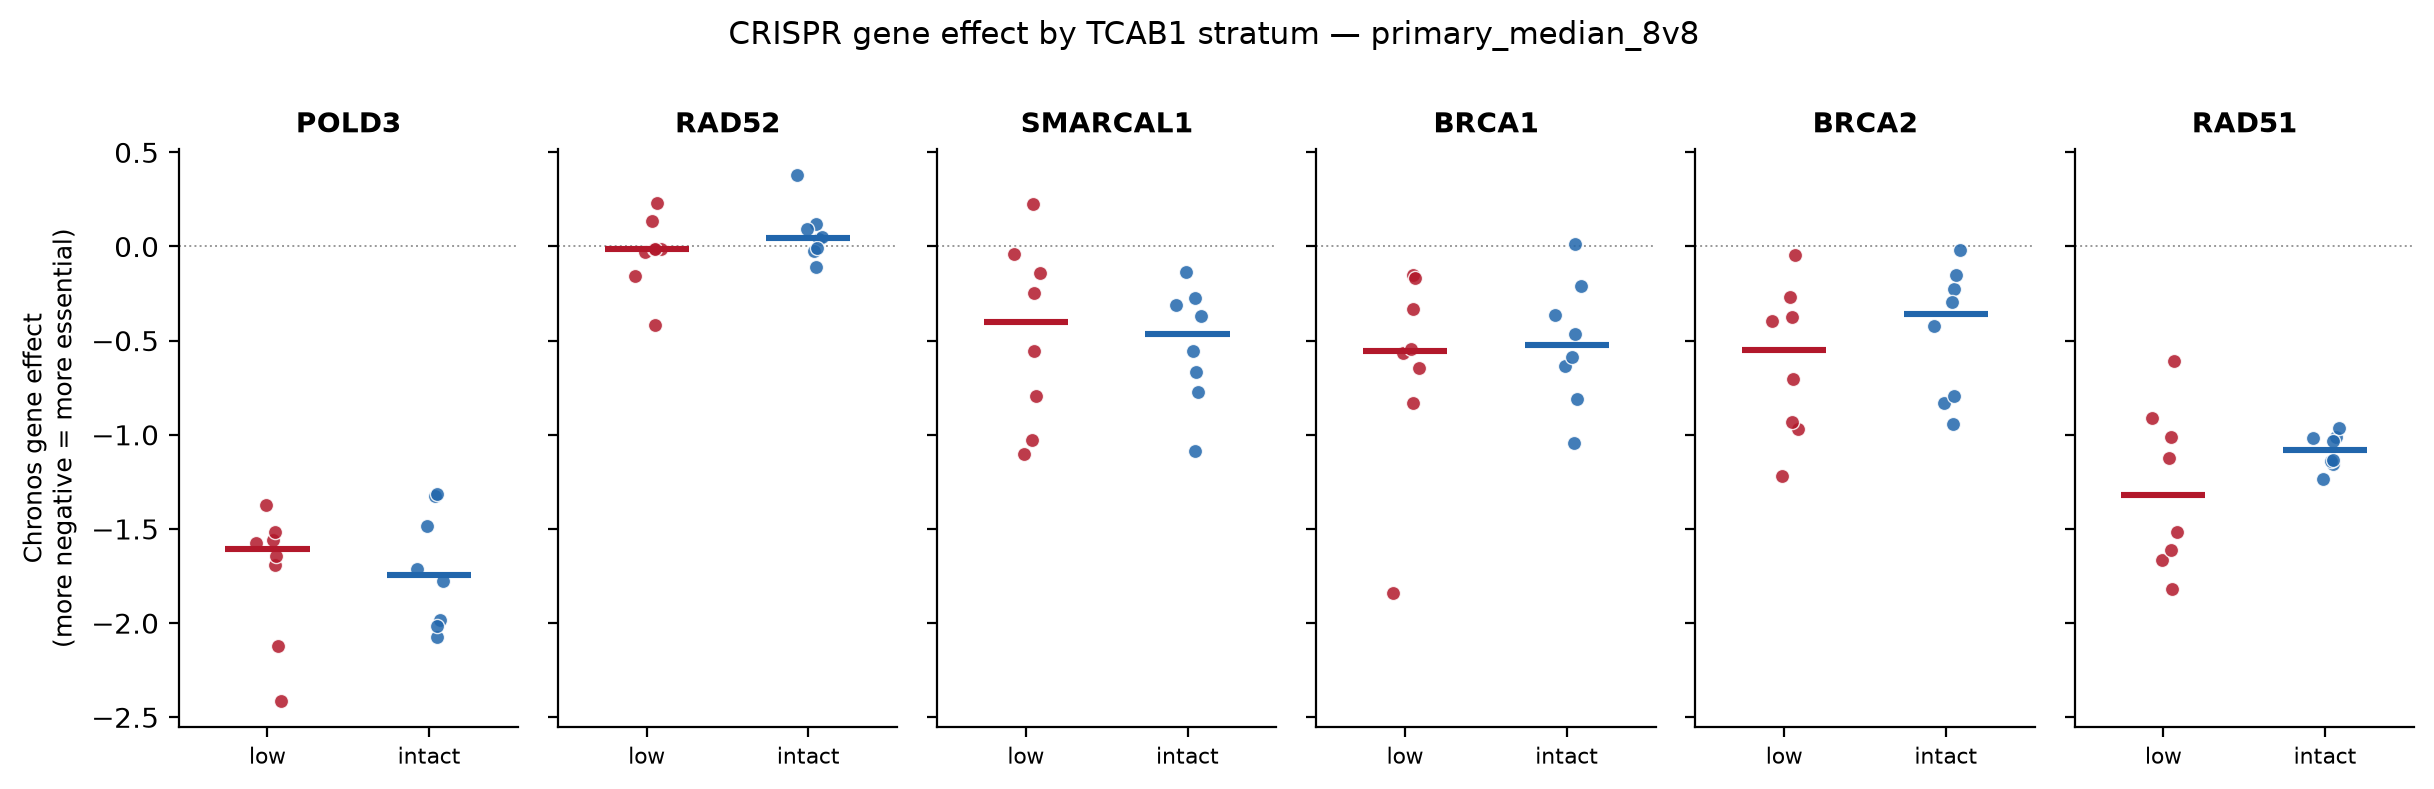

wrote figures/forest_primary_median_8v8.png


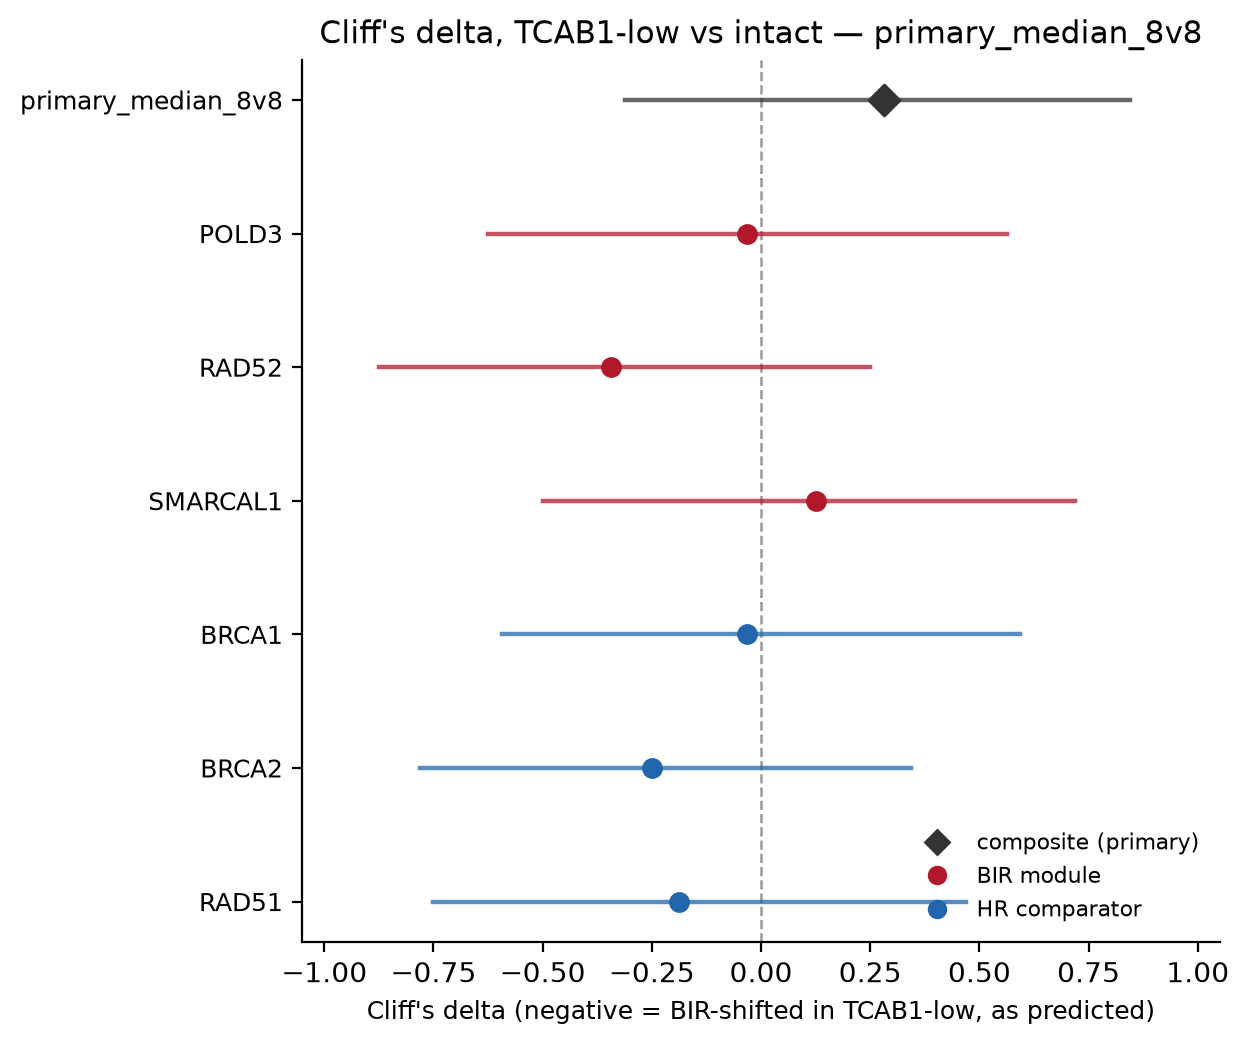

wrote figures/strip_sensitivity_tertile_3v13.png


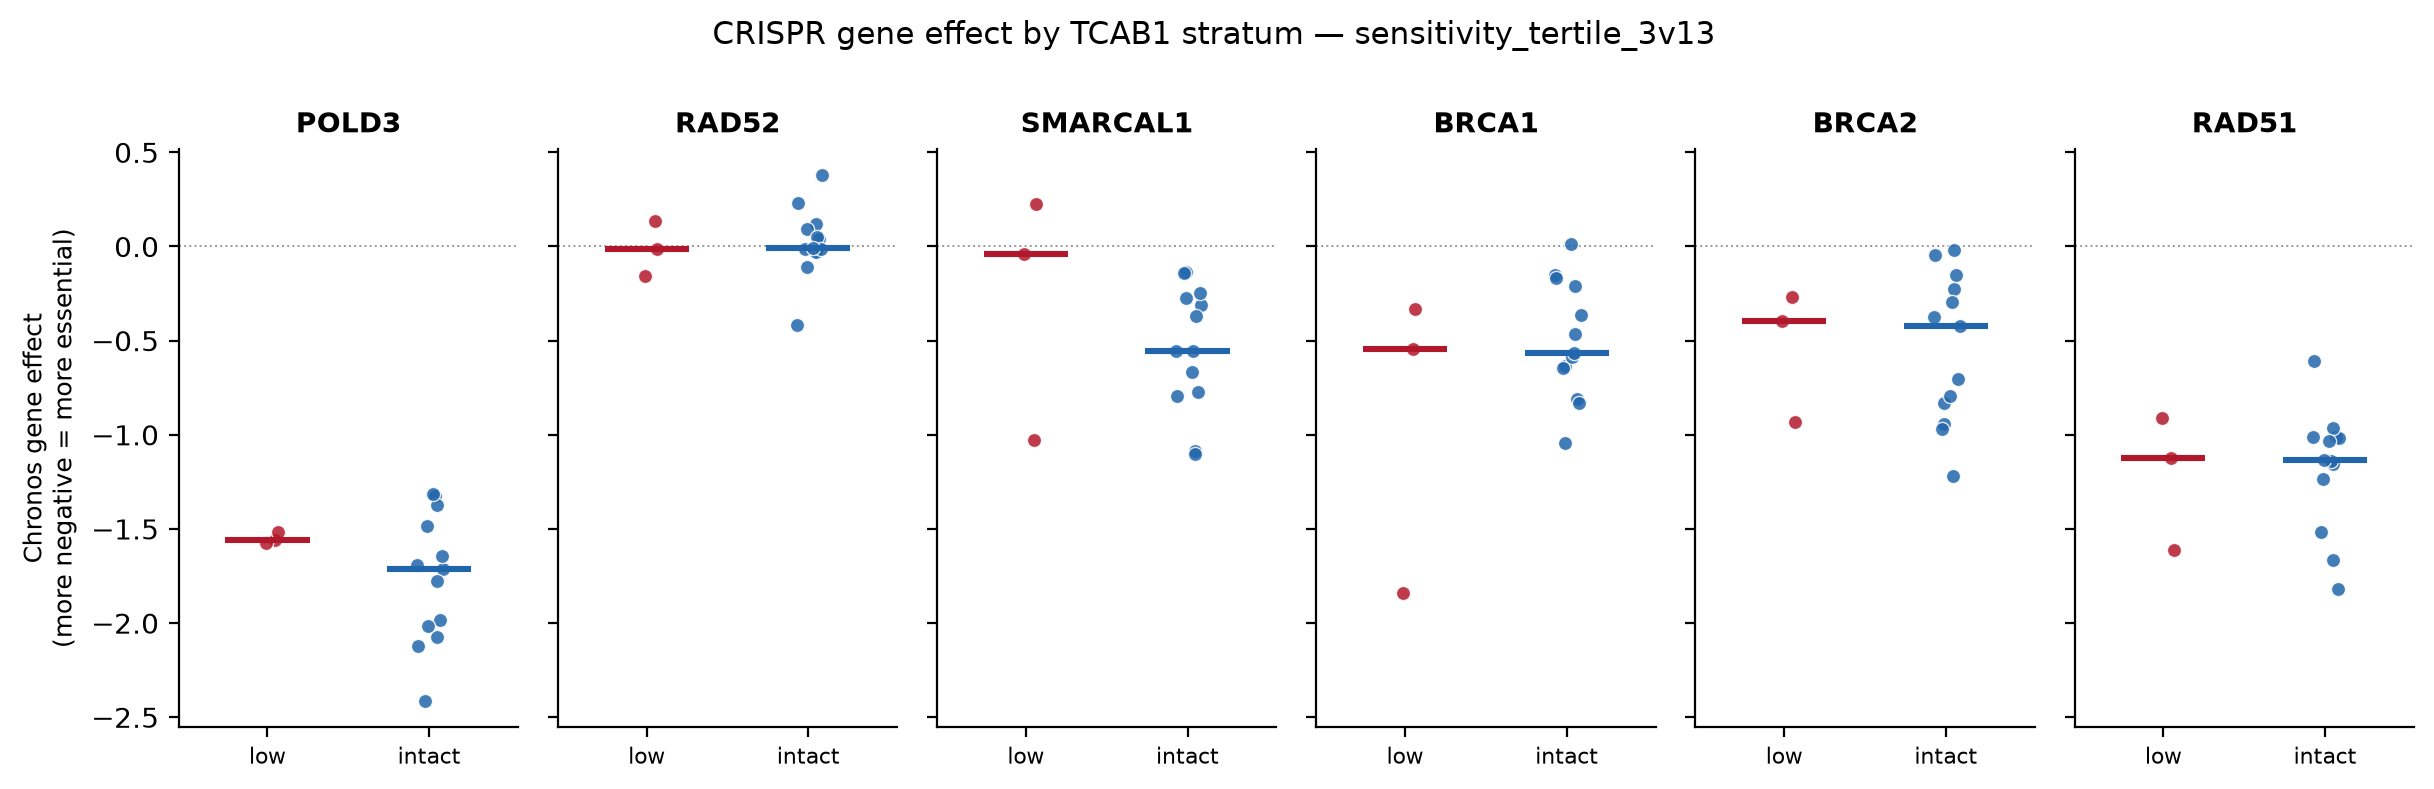

wrote figures/forest_sensitivity_tertile_3v13.png


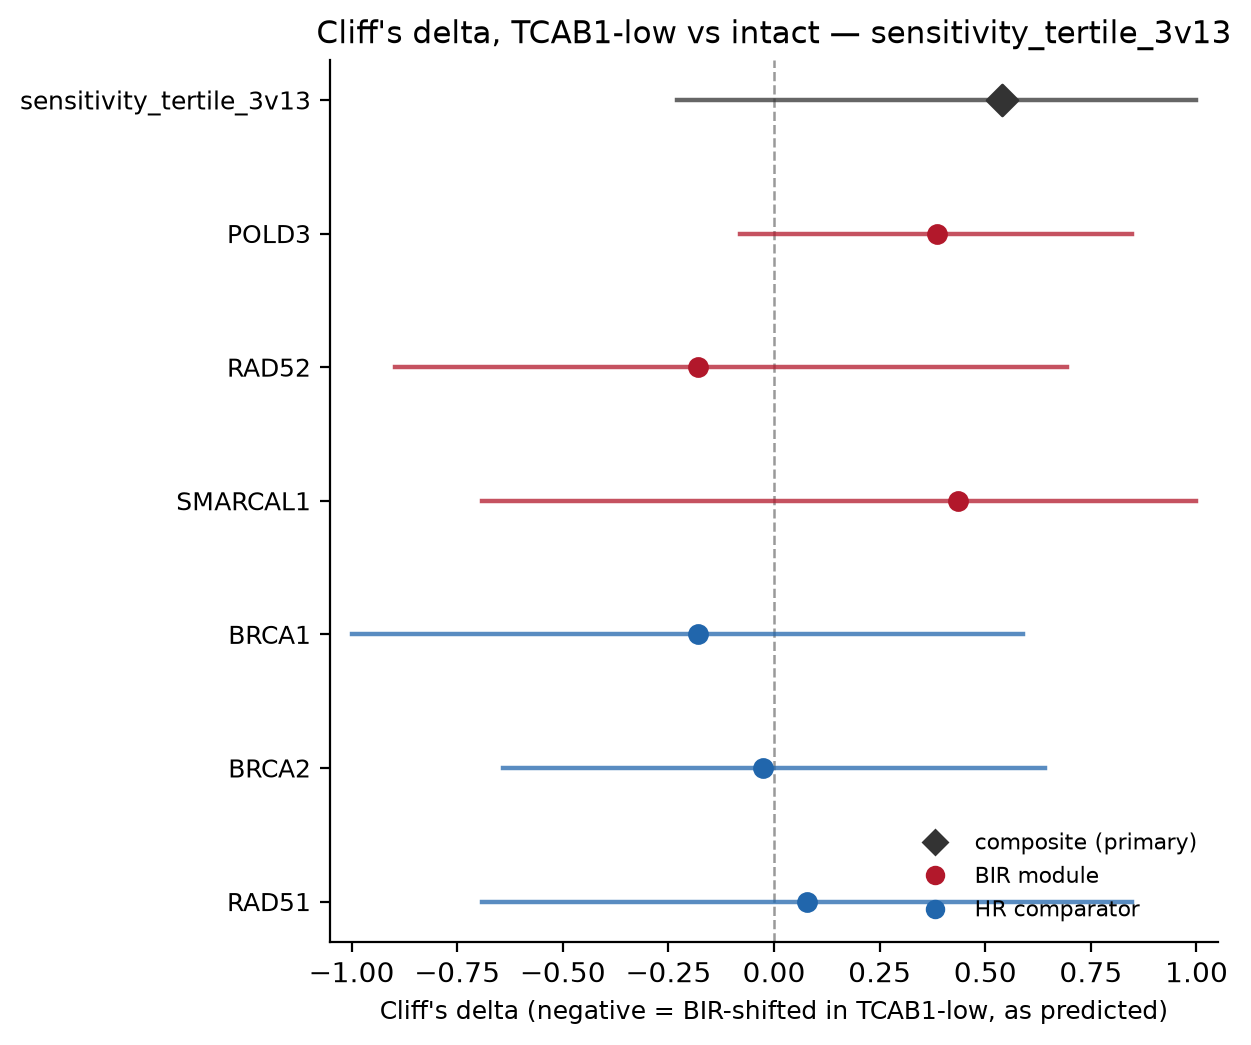

In [10]:
from src.plots import strip_plot, forest_plot
from IPython.display import Image, display

figs = []
for label, col in CONTRASTS.items():
    arms = strata[col].reindex(alt_ids)
    p = strip_plot(
        effects.loc[alt_ids], arms, SIX_GENES,
        title=f'CRISPR gene effect by TCAB1 stratum — {label}',
        outpath=ROOT / 'figures' / f'strip_{label}.png',
    )
    figs.append(p)
    f = forest_plot(
        per_gene[label], primary=results[label].as_dict(),
        title=f"Cliff's delta, TCAB1-low vs intact — {label}",
        outpath=ROOT / 'figures' / f'forest_{label}.png',
    )
    figs.append(f)
for p in figs:
    print(f'wrote {p.relative_to(ROOT)}')
    display(Image(filename=str(p)))

## 11 — Persist and report

In [11]:
import json as _json

primary_path = PROCESSED_DIR / 'primary_result.json'
payload = {
    'prespec_freeze_v1_0': FREEZE_COMMIT_V10,
    'prespec_amend_v1_1': FREEZE_COMMIT_V11,
    'contrasts': {k: v.as_dict() for k, v in results.items()},
    'r1_gold_only': {k: (v.as_dict() if v is not None else None) for k, v in r1.items()},
    'concentration_section_6_4': conc,
    'min_detectable_delta': {k: float(v) for k, v in MIN_DETECTABLE_DELTA.items()},
}
primary_path.write_text(_json.dumps(payload, indent=2, sort_keys=True) + '\n')

per_gene_path = PROCESSED_DIR / 'per_gene_results.csv'
pg_all = []
for label, frame in per_gene.items():
    t = frame.copy(); t.insert(0, 'contrast', label); pg_all.append(t)
pd.concat(pg_all, ignore_index=True).to_csv(per_gene_path, index=False)

composite_path = PROCESSED_DIR / 'composite_scores.csv'
summary.to_csv(composite_path)

def _res_block(label, res):
    return [
        f'### {label}',
        '',
        f'- n: **{res.n_low}** TCAB1-low vs **{res.n_intact}** TCAB1-intact',
        f'- median composite: low **{res.median_low:+.4f}**, intact **{res.median_intact:+.4f}**',
        f'- Mann-Whitney U = {res.u_statistic:.1f}, two-sided **p = {res.p_value:.4g}** ({res.mwu_method})',
        f"- Cliff's delta = **{res.cliffs_delta:+.4f}**, 95% CI "
        f'[{res.delta_ci_low:+.4f}, {res.delta_ci_high:+.4f}] ({res.delta_magnitude})',
        f'- Hodges-Lehmann shift = **{res.hodges_lehmann:+.4f}** Chronos units',
        f'- direction as predicted (delta < 0): **{res.direction_as_predicted}**',
        '',
    ]

lines = [
    '# Notebook 05 — Primary essentiality comparison',
    '',
    f'First notebook to read the outcome. Pre-specification frozen at `{FREEZE_COMMIT_V10}`',
    f'(v1.0) and amended at `{FREEZE_COMMIT_V11}` (v1.1), both before this notebook ran.',
    '',
    '## Endpoint',
    '',
    '```',
    'composite = mean(POLD3, RAD52, SMARCAL1) - mean(BRCA1, BRCA2, RAD51)',
    '```',
    '',
    'Chronos gene effect is more negative when a gene is more essential, so the',
    'hypothesis predicts a **more negative** composite in TCAB1-low lines, i.e.',
    "Cliff's delta < 0. Tests are two-sided exact Mann-Whitney.",
    '',
    '## Primary and parallel sensitivity contrast',
    '',
]
lines += _res_block('primary_median_8v8 (PRIMARY)', results['primary_median_8v8'])
lines += _res_block('sensitivity_tertile_3v13 (pre-specified sensitivity)',
                    results['sensitivity_tertile_3v13'])
lines += [
    '## Minimum detectable effect (prespec §5a)',
    '',
    '| Contrast | Observed delta | min \|delta\| for p<0.05 | Significance reachable |',
    '|---|---|---|---|',
]
for label, key in [('primary_median_8v8', '8v8'), ('sensitivity_tertile_3v13', '3v13')]:
    res = results[label]; floor = MIN_DETECTABLE_DELTA[key]
    lines.append(f'| {label} | {res.cliffs_delta:+.4f} | {floor:.3f} | '
                 f'{"yes" if abs(res.cliffs_delta) >= floor else "no"} |')
lines += [
    '',
    '## R1 gold-only sensitivity',
    '',
    '| Contrast | n low | n intact | p | delta | Direction as predicted |',
    '|---|---|---|---|---|---|',
]
for label, res in r1.items():
    if res is None:
        lines.append(f'| {label} | — | — | not estimable | — | — |')
    else:
        lines.append(f'| {label} | {res.n_low} | {res.n_intact} | {res.p_value:.4g} '
                     f'| {res.cliffs_delta:+.4f} | {res.direction_as_predicted} |')
lines += [
    '',
    '## Six per-gene comparisons, BH-FDR across the six (§6.1)',
    '',
]
for label, frame in per_gene.items():
    lines += [
        f'### {label}',
        '',
        '| Gene | Set | median low | median intact | p | q (BH) | delta | 95% CI | HL | Magnitude |',
        '|---|---|---|---|---|---|---|---|---|---|',
    ]
    for _, r in frame.iterrows():
        lines.append(
            f"| {r['name']} | {r['gene_set']} | {r['median_low']:+.4f} "
            f"| {r['median_intact']:+.4f} | {r['p_value']:.4g} | {r['q_value']:.4g} "
            f"| {r['cliffs_delta']:+.4f} | [{r['delta_ci_low']:+.3f}, {r['delta_ci_high']:+.3f}] "
            f"| {r['hodges_lehmann']:+.4f} | {r['delta_magnitude']} |"
        )
    lines.append('')
lines += [
    '## §6.4 concentration comparison (pre-registered, descriptive, non-gating)',
    '',
    f"- delta, 8v8 median primary: **{conc['delta_median_8v8']:+.4f}**",
    f"- delta, 3v13 tertile sensitivity: **{conc['delta_tertile_3v13']:+.4f}**",
    f"- \|delta\| excess of tertile over median: **{conc['abs_excess_tertile_over_median']:+.4f}** "
    f"(threshold {conc['threshold']})",
    f"- concentrates in extreme-loss lines: **{conc['concentrates_in_extreme_loss']}**",
    '',
    conc['interpretation'],
    '',
    '## Figures',
    '',
] + [f'- `{p.relative_to(ROOT)}`' for p in figs] + [
    '',
    '## Not yet run',
    '',
    'Robustness (R2-R8), the §6.2 ALT- selectivity control, the §6.3 within-line',
    'standardised sensitivity, and the §8/§9/§10 verdict are notebooks 06 and 07.',
    'No verdict is drawn here.',
]
report = write_report('05', lines)
manifest = write_sha256_manifest('05', [report, primary_path, per_gene_path, composite_path])
record_provenance([{
    'notebook': '05', 'run_timestamp': RUN_TIMESTAMP,
    'prespec_freeze': FREEZE_COMMIT_V10, 'prespec_amend': FREEZE_COMMIT_V11,
    'primary_p': results['primary_median_8v8'].p_value,
    'primary_delta': results['primary_median_8v8'].cliffs_delta,
    'tertile_p': results['sensitivity_tertile_3v13'].p_value,
    'tertile_delta': results['sensitivity_tertile_3v13'].cliffs_delta,
}])
print(f'wrote {primary_path.name}, {per_gene_path.name}, {composite_path.name}')
print(f'wrote {report.name}, {manifest.name}')

wrote primary_result.json, per_gene_results.csv, composite_scores.csv
wrote notebook_05_report.md, notebook_05_sha256.json


<>:62: SyntaxWarning: invalid escape sequence '\|'
<>:107: SyntaxWarning: invalid escape sequence '\|'
<>:62: SyntaxWarning: invalid escape sequence '\|'
<>:107: SyntaxWarning: invalid escape sequence '\|'
/var/folders/nf/xqdlm_z563154070j2mx6cwh0000gn/T/ipykernel_21463/3473443219.py:62: SyntaxWarning: invalid escape sequence '\|'
  '| Contrast | Observed delta | min \|delta\| for p<0.05 | Significance reachable |',
/var/folders/nf/xqdlm_z563154070j2mx6cwh0000gn/T/ipykernel_21463/3473443219.py:107: SyntaxWarning: invalid escape sequence '\|'
  f"- \|delta\| excess of tertile over median: **{conc['abs_excess_tertile_over_median']:+.4f}** "
